# Day 15 — Anomaly Detection Baseline

## Objective

The objective of Day 15 is to establish baseline anomaly-detection methods for the time-stamped water-quality dataset.

Two approaches will be evaluated:

1. A simple statistical/rule-based anomaly baseline.
2. An Isolation Forest machine-learning anomaly detector.

The detected anomalies will be visualised and the evaluation strategy will be documented for future experiments.

## Dataset

The analysis uses the engineered training, validation, and test datasets created during Day 13.

## Evaluation Strategy

Since the current dataset does not contain ground-truth anomaly labels, initial evaluation will focus on:

- Number and proportion of observations flagged as anomalies
- Distribution of anomaly scores
- Visual inspection of detected anomalies over time
- Comparison between the statistical baseline and Isolation Forest

If validated anomaly labels become available later, precision, recall, F1-score, and confusion matrices will be used for quantitative evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

base_path = r"C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics\data\processed"

train_df = pd.read_csv(base_path + r"\train_v1_engineered.csv")
val_df = pd.read_csv(base_path + r"\validation_v1_engineered.csv")
test_df = pd.read_csv(base_path + r"\test_v1_engineered.csv")

for data in [train_df, val_df, test_df]:
    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        errors="coerce"
    )

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (2291, 42)
Validation: (491, 42)
Test: (491, 42)


In [3]:
sensor_cols = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity"
]

print("Sensor features:")
print(sensor_cols)

print("\nNumber of sensor features:", len(sensor_cols))

Sensor features:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

Number of sensor features: 9


In [4]:
# Calculate mean and standard deviation using TRAIN data only

train_mean = train_df[sensor_cols].mean()
train_std = train_df[sensor_cols].std()

# Calculate Z-scores for each dataset
for data in [train_df, val_df, test_df]:
    z_scores = ((data[sensor_cols] - train_mean) / train_std).abs()
    
    # An observation is an anomaly if any sensor has |Z-score| > 3
    data["rule_anomaly"] = z_scores.gt(3).any(axis=1)

# Display anomaly counts
print("Statistical Rule-Based Anomaly Results")
print("--------------------------------------")

print("Train anomalies:", train_df["rule_anomaly"].sum())
print("Validation anomalies:", val_df["rule_anomaly"].sum())
print("Test anomalies:", test_df["rule_anomaly"].sum())

print("\nAnomaly percentages:")
print("Train:", round(train_df["rule_anomaly"].mean() * 100, 2), "%")
print("Validation:", round(val_df["rule_anomaly"].mean() * 100, 2), "%")
print("Test:", round(test_df["rule_anomaly"].mean() * 100, 2), "%")

Statistical Rule-Based Anomaly Results
--------------------------------------
Train anomalies: 78
Validation anomalies: 20
Test anomalies: 23

Anomaly percentages:
Train: 3.4 %
Validation: 4.07 %
Test: 4.68 %


In [5]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer

# Handle missing sensor values using training-data medians
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(train_df[sensor_cols])
X_val = imputer.transform(val_df[sensor_cols])
X_test = imputer.transform(test_df[sensor_cols])

# Train Isolation Forest
isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

isolation_forest.fit(X_train)

# Predict anomalies
train_pred = isolation_forest.predict(X_train)
val_pred = isolation_forest.predict(X_val)
test_pred = isolation_forest.predict(X_test)

# Convert predictions to True/False
train_df["if_anomaly"] = train_pred == -1
val_df["if_anomaly"] = val_pred == -1
test_df["if_anomaly"] = test_pred == -1

# Anomaly scores: higher value = more anomalous
train_df["if_score"] = -isolation_forest.decision_function(X_train)
val_df["if_score"] = -isolation_forest.decision_function(X_val)
test_df["if_score"] = -isolation_forest.decision_function(X_test)

print("Isolation Forest Results")
print("-----------------------")

print("Train anomalies:", train_df["if_anomaly"].sum())
print("Validation anomalies:", val_df["if_anomaly"].sum())
print("Test anomalies:", test_df["if_anomaly"].sum())

print("\nAnomaly percentages:")
print("Train:", round(train_df["if_anomaly"].mean() * 100, 2), "%")
print("Validation:", round(val_df["if_anomaly"].mean() * 100, 2), "%")
print("Test:", round(test_df["if_anomaly"].mean() * 100, 2), "%")

Isolation Forest Results
-----------------------
Train anomalies: 115
Validation anomalies: 28
Test anomalies: 14

Anomaly percentages:
Train: 5.02 %
Validation: 5.7 %
Test: 2.85 %


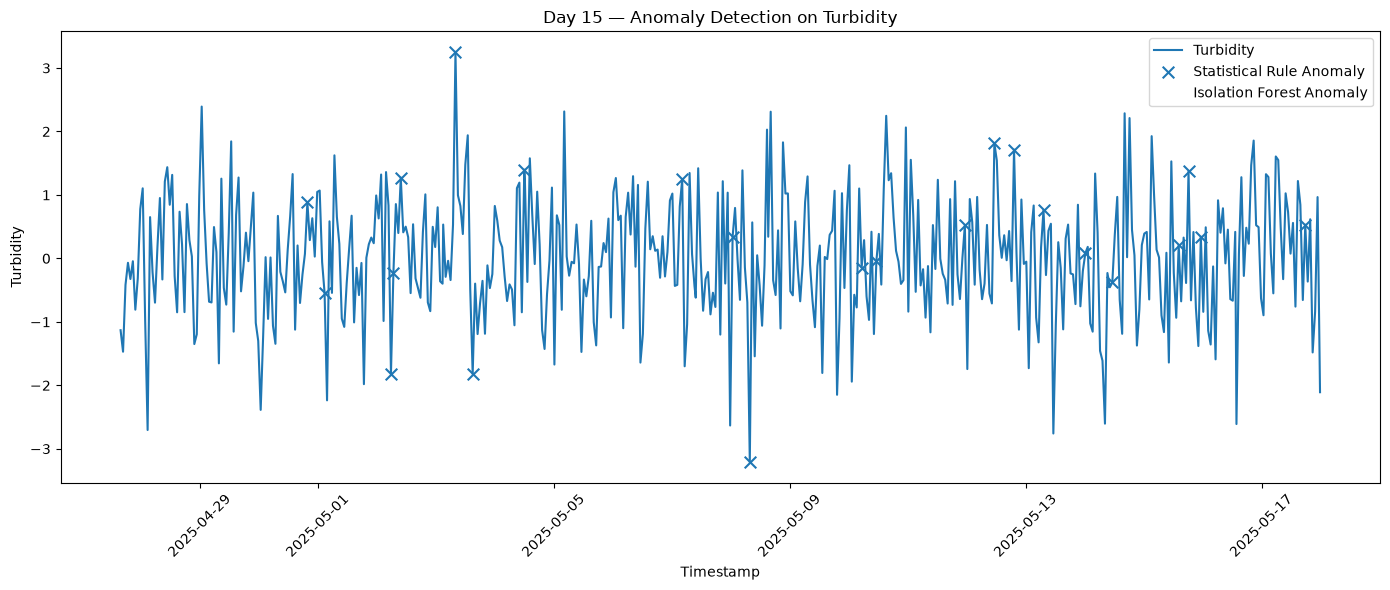

In [6]:
# Sort test data by timestamp for visualization
plot_df = test_df.sort_values("timestamp").copy()

# Plot Turbidity with detected anomalies
plt.figure(figsize=(14, 6))

plt.plot(
    plot_df["timestamp"],
    plot_df["Turbidity"],
    label="Turbidity"
)

# Statistical rule anomalies
rule_points = plot_df[plot_df["rule_anomaly"]]

plt.scatter(
    rule_points["timestamp"],
    rule_points["Turbidity"],
    label="Statistical Rule Anomaly",
    marker="x",
    s=70
)

# Isolation Forest anomalies
if_points = plot_df[plot_df["if_anomaly"]]

plt.scatter(
    if_points["timestamp"],
    if_points["Turbidity"],
    label="Isolation Forest Anomaly",
    marker="o",
    facecolors="none",
    s=80
)

plt.title("Day 15 — Anomaly Detection on Turbidity")
plt.xlabel("Timestamp")
plt.ylabel("Turbidity")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

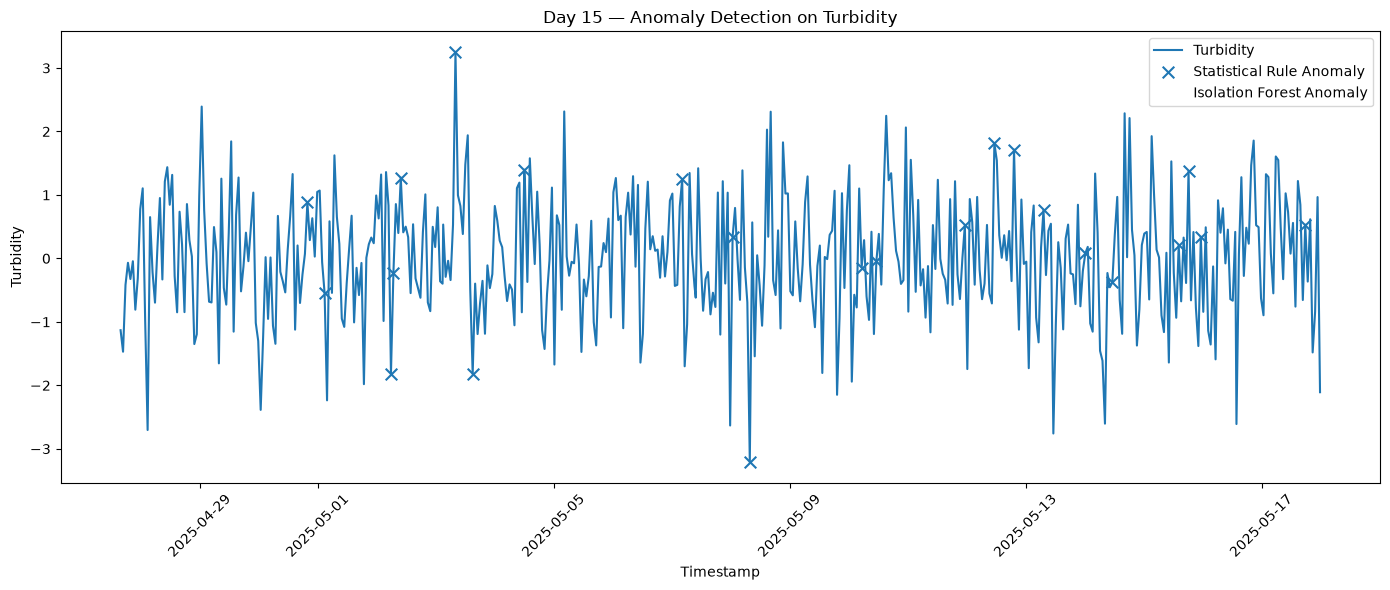

In [8]:
# Sort test data by timestamp for visualization
plot_df = test_df.sort_values("timestamp").copy()

# Plot Turbidity with detected anomalies
plt.figure(figsize=(14, 6))

plt.plot(
    plot_df["timestamp"],
    plot_df["Turbidity"],
    label="Turbidity"
)

# Statistical rule anomalies
rule_points = plot_df[plot_df["rule_anomaly"]]

plt.scatter(
    rule_points["timestamp"],
    rule_points["Turbidity"],
    label="Statistical Rule Anomaly",
    marker="x",
    s=70
)

# Isolation Forest anomalies
if_points = plot_df[plot_df["if_anomaly"]]

plt.scatter(
    if_points["timestamp"],
    if_points["Turbidity"],
    label="Isolation Forest Anomaly",
    marker="o",
    facecolors="none",
    s=80
)

plt.title("Day 15 — Anomaly Detection on Turbidity")
plt.xlabel("Timestamp")
plt.ylabel("Turbidity")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Day 15 — Evaluation Strategy

## Initial Evaluation Strategy

The current dataset does not contain ground-truth anomaly labels. Therefore, supervised metrics such as precision, recall, and F1-score cannot yet be used to validate anomaly detections.

For the initial anomaly-detection baseline, evaluation will use:

1. **Anomaly count** — number of observations flagged as anomalous.
2. **Anomaly rate** — percentage of observations flagged as anomalous.
3. **Anomaly score distribution** — distribution of Isolation Forest anomaly scores.
4. **Temporal visualization** — inspection of detected anomalies over time.
5. **Method comparison** — comparison between the statistical Z-score rule and Isolation Forest.

## Statistical Baseline

A Z-score threshold of |Z| > 3 was used as the initial statistical rule.

The mean and standard deviation were calculated using training data only and then applied to validation and test data.

## Isolation Forest

Isolation Forest was used as the machine-learning anomaly detector.

The initial contamination assumption was set to 5%. This is a baseline configuration and will be evaluated or adjusted during later experiments.

## Future Quantitative Evaluation

If reliable ground-truth anomaly labels become available, the following metrics will be used:

- Precision
- Recall
- F1-score
- Confusion matrix

This evaluation strategy will be revisited after mentor feedback and during advanced anomaly-detection experiments.

# Day 15 Summary

## Completed Work

- Loaded the engineered time-series datasets.
- Selected the 9 raw water-quality sensor variables for anomaly detection.
- Implemented a statistical Z-score anomaly baseline.
- Implemented an Isolation Forest anomaly detector.
- Used training data statistics to reduce data leakage.
- Handled missing sensor values using training-set median imputation.
- Generated anomaly flags and Isolation Forest anomaly scores.
- Visualised detected anomalies over time.
- Defined the initial evaluation strategy.

## Anomaly Detection Methods

### 1. Statistical Rule-Based Baseline

An observation is flagged as anomalous when at least one sensor has an absolute Z-score greater than 3.

### 2. Isolation Forest

Isolation Forest identifies observations that are relatively isolated from the normal data distribution.

An initial contamination value of 5% was used as a baseline assumption.

## Visualisations

The following plots were generated:

- Turbidity with statistical and Isolation Forest anomaly markers
- Isolation Forest anomaly scores over time

## Limitations

The current dataset does not contain verified ground-truth anomaly labels. Therefore, the detected anomalies should currently be treated as candidate anomalies rather than confirmed environmental events.

## Next Steps

Future work will evaluate anomaly-detection methods more rigorously and investigate forecasting of future water-quality parameters.